# ClockMesh — three Movella DOTs on the common N3 node timeline

**Capture:** `20261113T115729.279476Z_14b53cd8`  
**Acquisition:** DOT sensor clock → BLE Gateway clock → N3 node monotonic clock.  
**Question:** Do all three movement signals share a coherent timeline after the two ClockMesh mappings are composed?

This notebook uses the **existing, already-computed** `session_time_ns` values. It does not refit the clock models, modify timestamp mappings, shift signals, or alter the data collection implementation. The principal comparison is the *zero-added-lag* agreement of the three rigidly mounted sensors' gyroscope magnitudes.

The source files remain in your tooling repository; the notebook does not copy or package them.

## 1. Locate the capture and load its official measurement

From the `nexus-n3-ble-tooling` repository, or a subdirectory, the notebook finds:

`output-files/clock-mesh-node/20261113T115729.279476Z_14b53cd8`

If your Jupyter working directory is elsewhere, set `CAPTURE_DIR_OVERRIDE` to that folder. No source files need to be moved.

In [1]:
from pathlib import Path
from itertools import combinations
import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CAPTURE_ID = "20261113T115729.279476Z_14b53cd8"
CAPTURE_RELATIVE = Path("output-files") / "clock-mesh-node" / CAPTURE_ID
CAPTURE_DIR_OVERRIDE = None  # e.g. Path("/path/to/nexus-n3-ble-tooling/output-files/clock-mesh-node") / CAPTURE_ID

# User options: edit these and re-run the notebook for another motion feature.
ZOOM_START_S = None          # None selects a strong gyro motion peak automatically.
ZOOM_WIDTH_S = 3.0
LAG_SEARCH_MS = 50           # Diagnostics only; NEVER used to shift the main plots.
LAG_STEP_MS = 1              # Interpolated diagnostic; not timing-measurement resolution.

candidates = []
if CAPTURE_DIR_OVERRIDE is not None:
    candidates.append(Path(CAPTURE_DIR_OVERRIDE).expanduser())
if os.environ.get("CLOCKMESH_CAPTURE_DIR"):
    candidates.append(Path(os.environ["CLOCKMESH_CAPTURE_DIR"]).expanduser())
for root in (Path.cwd(), *Path.cwd().parents):
    candidates.append(root / CAPTURE_RELATIVE)
# Useful when a Jupyter server is launched outside the project directory.
candidates.append(Path.home() / "Desktop/apps/dev/rs-nexus-project/nexus-n3-ble-tooling" / CAPTURE_RELATIVE)

capture_dir = next((p.resolve() for p in candidates if (p / "observations.csv").is_file()), None)
if capture_dir is None:
    searched = "\n".join(f"  {p}" for p in candidates)
    raise FileNotFoundError(
        f"Could not locate observations.csv for capture {CAPTURE_ID}.\n"
        f"Set CAPTURE_DIR_OVERRIDE to the capture directory.\nSearched:\n{searched}"
    )

with (capture_dir / "manifest.json").open(encoding="utf-8") as f:
    manifest = json.load(f)
with (capture_dir / "summary.json").open(encoding="utf-8") as f:
    summary = json.load(f)

observations = pd.read_csv(capture_dir / "observations.csv")
required = {
    "sensor_id", "address", "stream_phase", "session_time_ns", "mapped_node_ns",
    "mapped_gateway_ns", "gyro_x_deg_s", "gyro_y_deg_s", "gyro_z_deg_s",
    "accel_x_m_s2", "accel_y_m_s2", "accel_z_m_s2",
}
missing = required - set(observations.columns)
if missing:
    raise ValueError(f"Required fields missing from observations.csv: {sorted(missing)}")

assert summary.get("status") == "completed", "Capture did not complete successfully."
dot = observations.loc[observations["stream_phase"].eq("measurement")].copy()
dot = dot.dropna(subset=["session_time_ns", "mapped_node_ns", "mapped_gateway_ns"])
assert dot["sensor_id"].nunique() == 3, "Expected exactly three DOTs in official measurement."

# Time is on the node clock: use the test client's composed session timestamps.
dot["node_time_s"] = dot["session_time_ns"].astype("int64") / 1e9
dot["gyro_magnitude_deg_s"] = np.linalg.norm(
    dot[["gyro_x_deg_s", "gyro_y_deg_s", "gyro_z_deg_s"]].to_numpy(dtype=float), axis=1
)
dot["accel_magnitude_m_s2"] = np.linalg.norm(
    dot[["accel_x_m_s2", "accel_y_m_s2", "accel_z_m_s2"]].to_numpy(dtype=float), axis=1
)

DOTS = {
    int(sid): group.sort_values("node_time_s").reset_index(drop=True)
    for sid, group in dot.groupby("sensor_id", sort=True)
}
LABELS = {sid: f"DOT {sid} · {g['address'].iloc[0][-5:]}" for sid, g in DOTS.items()}
IDS = sorted(DOTS)

# The official origin is one shared node monotonic timestamp.
origin_ns = int(summary["official_start_node_monotonic_ns"])
origin_difference_ns = (
    dot["mapped_node_ns"].to_numpy(dtype=np.int64) - origin_ns
    - dot["session_time_ns"].to_numpy(dtype=np.int64)
)
assert np.all(origin_difference_ns == 0), "Session times do not match the stored node-time origin."

print(f"Capture: {CAPTURE_RELATIVE} (located successfully)")
print(f"Status: {summary['status']}; official duration: {summary['official_elapsed_seconds']:.3f} s")
print(f"Node origin: {origin_ns} ns (time.monotonic_ns domain)")
print(f"Official observations: {len(dot):,}; sensors: {len(DOTS)}")

Capture: output-files/clock-mesh-node/20261113T115729.279476Z_14b53cd8 (located successfully)
Status: completed; official duration: 30.001 s
Node origin: 22317585968537 ns (time.monotonic_ns domain)
Official observations: 5,399; sensors: 3


## 2. Verify that the composed timeline exists and is continuous

For each DOT, `session_time_ns` must increase in source-sample order. The values are derived from **two mappings**, not from the order in which packets arrive at the host. Each DOT can therefore have a monotonically increasing sample timeline even if packets from the three DOTs are interleaved during transport.

The last column reports *per-sensor* monotonicity; there is no requirement that interleaved frames from different sensors arrive in chronological sample order.

In [2]:
rows = []
missing_by_id = summary.get("dot_counts_by_phase", {}).get("measurement", {})
for sid, g in DOTS.items():
    t = g["node_time_s"].to_numpy(dtype=float)
    diffs = np.diff(t)
    rows.append({
        "sensor": LABELS[sid],
        "official samples": len(g),
        "first node time (s)": t[0],
        "last node time (s)": t[-1],
        "median interval (ms)": 1e3 * np.median(diffs),
        "non-increasing steps": int(np.sum(diffs <= 0)),
        "inferred missing": missing_by_id.get(str(sid), {}).get("inferred_missing_samples", np.nan),
    })
continuity = pd.DataFrame(rows).set_index("sensor")
display(continuity.round(5))

print("Shared origin check: all official session_time_ns values equal mapped_node_ns minus official_start_node_monotonic_ns.")
print("No additional alignment or per-sensor time shift has been applied.")

,official samples,first node time (s),last node time (s),median interval (ms),non-increasing steps,inferred missing
sensor,,,,,,
DOT 0 · B4:5E,1800,0.00133,29.98668,16.66769,0,0
DOT 1 · B8:3E,1799,0.00946,29.97778,16.66786,0,0
DOT 2 · B4:43,1800,0.00070,29.98608,16.66772,0,0


Shared origin check: all official session_time_ns values equal mapped_node_ns minus official_start_node_monotonic_ns.
No additional alignment or per-sensor time shift has been applied.


## 3. Full recording — three movement signals on one node timeline

The plot below uses each observation's **composed node-reference timestamp**. The vertical axis is gyroscope magnitude, independent of how an individual DOT was oriented on the rigid mount:

`gyro magnitude = sqrt(gyro_x² + gyro_y² + gyro_z²)`

If the mappings produce a coherent shared timeline and the sensors underwent the same rotations, their motion peaks should largely coincide. Unlike a receive-time plot, BLE and serial buffering do not determine the horizontal position of individual samples.

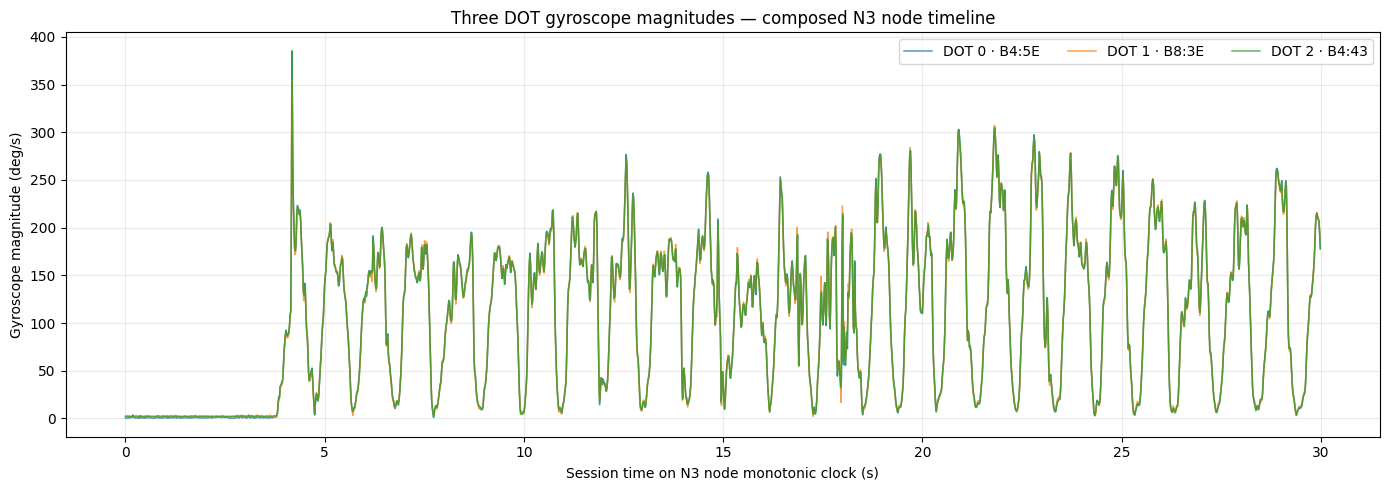

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))
for sid, g in DOTS.items():
    ax.plot(g["node_time_s"], g["gyro_magnitude_deg_s"],
            linewidth=1.1, alpha=0.75, label=LABELS[sid])
ax.set(title="Three DOT gyroscope magnitudes — composed N3 node timeline",
       xlabel="Session time on N3 node monotonic clock (s)",
       ylabel="Gyroscope magnitude (deg/s)")
ax.grid(alpha=0.25)
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 4. Close-up — do the individual peaks coincide?

The default zoom centres on DOT 0's largest gyroscope-magnitude peak, typically a useful part of this recording to compare. Set `ZOOM_START_S` in Section 1 to inspect any other portion of the official recording.

The dots identify the original ~60 Hz samples. The lines connect those samples; **no resampling or time correction** is performed for this figure. The second panel shows acceleration magnitude as a secondary signal. Acceleration agreement may be lower because sensors at different positions on a rigid object can experience different linear and rotational accelerations, even when their angular motion agrees.

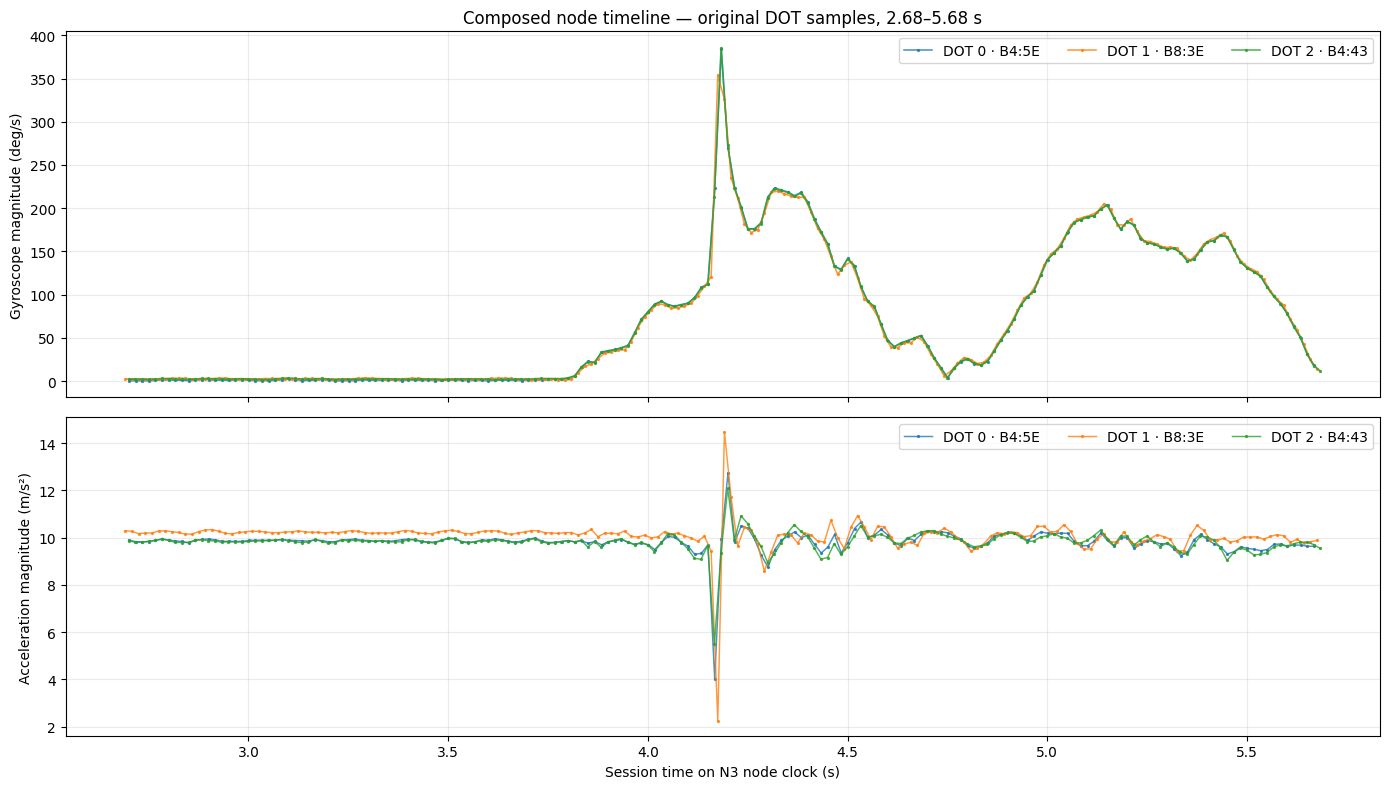

In [4]:
common_start_s = max(float(g["node_time_s"].iloc[0]) for g in DOTS.values())
common_end_s = min(float(g["node_time_s"].iloc[-1]) for g in DOTS.values())
assert common_end_s - common_start_s > ZOOM_WIDTH_S

if ZOOM_START_S is None:
    ref = DOTS[IDS[0]]
    peak_t = float(ref.loc[ref["gyro_magnitude_deg_s"].idxmax(), "node_time_s"])
    zoom_start_s = float(np.clip(peak_t - ZOOM_WIDTH_S / 2,
                                 common_start_s, common_end_s - ZOOM_WIDTH_S))
else:
    zoom_start_s = float(ZOOM_START_S)
zoom_end_s = zoom_start_s + ZOOM_WIDTH_S

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1.15, 1]})
for sid, g in DOTS.items():
    selection = g.loc[g["node_time_s"].between(zoom_start_s, zoom_end_s)]
    axes[0].plot(selection["node_time_s"], selection["gyro_magnitude_deg_s"],
                 ".-", markersize=2.7, linewidth=1.15, alpha=0.8, label=LABELS[sid])
    axes[1].plot(selection["node_time_s"], selection["accel_magnitude_m_s2"],
                 ".-", markersize=2.7, linewidth=1.05, alpha=0.8, label=LABELS[sid])
axes[0].set(ylabel="Gyroscope magnitude (deg/s)",
            title=f"Composed node timeline — original DOT samples, {zoom_start_s:.2f}–{zoom_end_s:.2f} s")
axes[1].set(xlabel="Session time on N3 node clock (s)",
            ylabel="Acceleration magnitude (m/s²)")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 5. Quantitative correlation — zero added lag

**Primary test:** interpolate the original gyroscope-magnitude measurements from all three DOTs onto the *same comparison grid* (60 Hz) **using their existing node timestamps**, then calculate Pearson correlation between each pair.

Interpolation is only used to evaluate values at common times. It does **not** refit timestamps, shift one sensor against another, or improve the ClockMesh models. The common grid is restricted to the region covered by all three streams. Results are shown both for the whole recording and for the selected zoom.

An `r` close to +1 shows similar waveform shape at the same node times. It does not independently measure absolute physical timing error.

In [5]:
GRID_HZ = 60.0
common_grid = np.arange(common_start_s, common_end_s, 1.0 / GRID_HZ)

def interpolate_signal(g, time_grid, signal_col, time_col="node_time_s"):
    return np.interp(time_grid,
                     g[time_col].to_numpy(dtype=float),
                     g[signal_col].to_numpy(dtype=float))

G = {sid: interpolate_signal(g, common_grid, "gyro_magnitude_deg_s")
     for sid, g in DOTS.items()}
A = {sid: interpolate_signal(g, common_grid, "accel_magnitude_m_s2")
     for sid, g in DOTS.items()}
zoom_mask = (common_grid >= zoom_start_s) & (common_grid <= zoom_end_s)

def pearson(a, b):
    if len(a) < 3 or np.std(a) == 0 or np.std(b) == 0:
        return float("nan")
    return float(np.corrcoef(a, b)[0, 1])

pairs = list(combinations(IDS, 2))
comparison_rows = []
for left, right in pairs:
    comparison_rows.append({
        "DOT pair": f"{LABELS[left]} ↔ {LABELS[right]}",
        "gyro r, full (zero lag)": pearson(G[left], G[right]),
        "gyro r, zoom (zero lag)": pearson(G[left][zoom_mask], G[right][zoom_mask]),
        "accel magnitude r, full": pearson(A[left], A[right]),
    })
comparison = pd.DataFrame(comparison_rows).set_index("DOT pair")
display(comparison.round(6))
print(f"Common interpolated comparison grid: {len(common_grid):,} samples at {GRID_HZ:g} Hz, "
      f"{common_start_s:.3f}–{common_end_s:.3f} s")
print("All headline correlations use zero additional lag.")

,"gyro r, full (zero lag)","gyro r, zoom (zero lag)","accel magnitude r, full"
DOT pair,,,
DOT 0 · B4:5E ↔ DOT 1 · B8:3E,0.999222,0.998046,0.816485
DOT 0 · B4:5E ↔ DOT 2 · B4:43,0.999970,0.999960,0.899486
DOT 1 · B8:3E ↔ DOT 2 · B4:43,0.999320,0.998376,0.548694


Common interpolated comparison grid: 1,799 samples at 60 Hz, 0.009–29.978 s
All headline correlations use zero additional lag.


## 6. Optional diagnostic — would an artificial time shift improve correlation?

This is a **sensitivity check**, not an extra clock mapping. We measure how correlation changes when one *interpolated signal* is evaluated slightly earlier or later (±50 ms by default).

If the correlation already peaks near 0 ms, no extra time shift is suggested by these waveforms. Do **not** feed the apparent best lag back into the timeline: a peak obtained from interpolation, finite sampling, mounting differences, and signal shape is **not** a calibrated physical synchronisation measurement.

**Sign convention:** a positive reported lag means that the second DOT's waveform has to be sampled at a *later* nominal node time to match the first, i.e. the second waveform appears later under this comparison.

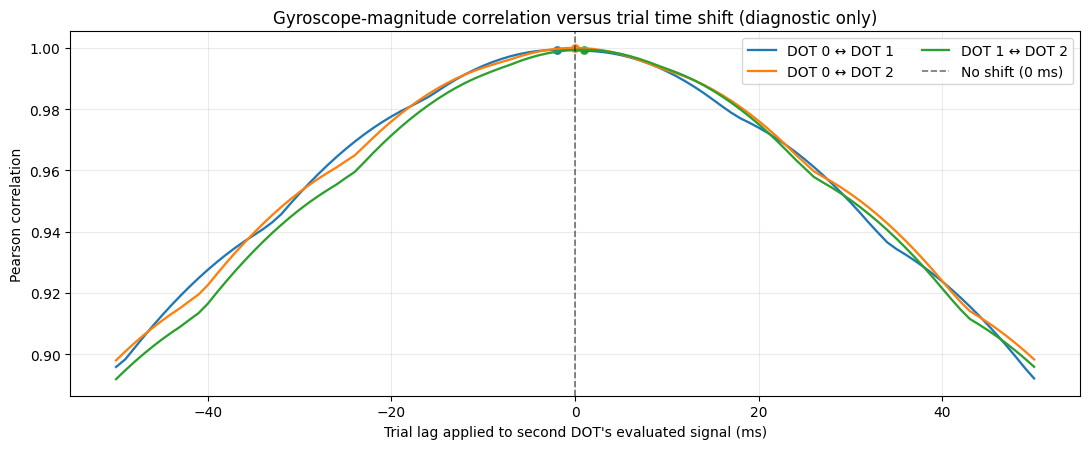

,zero-lag gyro r,highest interpolated r,apparent best lag (ms)
DOT pair,,,
DOT 0 · B4:5E ↔ DOT 1 · B8:3E,0.999222,0.999342,-2
DOT 0 · B4:5E ↔ DOT 2 · B4:43,0.999970,0.999970,0
DOT 1 · B8:3E ↔ DOT 2 · B4:43,0.999320,0.999373,1


In [6]:
lag_ms = np.arange(-LAG_SEARCH_MS, LAG_SEARCH_MS + LAG_STEP_MS, LAG_STEP_MS)
fig, ax = plt.subplots(figsize=(11, 4.6))
lag_rows = []
for left, right in pairs:
    reference = G[left]
    other = DOTS[right]
    other_t = other["node_time_s"].to_numpy(dtype=float)
    other_y = other["gyro_magnitude_deg_s"].to_numpy(dtype=float)
    correlations = []
    for lag in lag_ms:
        shifted_t = common_grid + lag / 1000.0
        valid = (shifted_t >= other_t[0]) & (shifted_t <= other_t[-1])
        shifted = np.interp(shifted_t[valid], other_t, other_y)
        correlations.append(pearson(reference[valid], shifted))
    correlations = np.asarray(correlations, dtype=float)
    best = int(np.nanargmax(correlations))
    lag_rows.append({
        "DOT pair": f"{LABELS[left]} ↔ {LABELS[right]}",
        "zero-lag gyro r": pearson(G[left], G[right]),
        "highest interpolated r": float(correlations[best]),
        "apparent best lag (ms)": int(lag_ms[best]),
    })
    ax.plot(lag_ms, correlations, label=f"DOT {left} ↔ DOT {right}", linewidth=1.65)
    ax.scatter([lag_ms[best]], [correlations[best]], s=28)
ax.axvline(0, linestyle="--", linewidth=1.2, color="black", alpha=0.55, label="No shift (0 ms)")
ax.set(title="Gyroscope-magnitude correlation versus trial time shift (diagnostic only)",
       xlabel="Trial lag applied to second DOT's evaluated signal (ms)",
       ylabel="Pearson correlation")
ax.grid(alpha=0.25)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

display(pd.DataFrame(lag_rows).set_index("DOT pair").round(6))

## 7. Sanity check — Gateway timeline versus composed node timeline

The node mapping is a further transformation of the existing sensor → Gateway mapping. As a useful **internal consistency check**, compute the same zero-added-lag gyroscope correlations once with `mapped_gateway_ns` and once with `mapped_node_ns`.

The correlations should remain similar if the composed mapping preserves the motion relationship. **This is not an independent synchronisation ground truth:** both results are derived from related fitted timestamp mappings.

In [7]:
# For this diagnostic only, express the Gateway mapping in relative seconds.
# Subtracting an arbitrary common gateway origin changes neither intervals nor correlations.
gateway_origin_ns = int(dot["mapped_gateway_ns"].min())
GATEWAY_DOTS = {}
for sid, g in DOTS.items():
    temp = g.copy()
    temp["gateway_time_s"] = (
        temp["mapped_gateway_ns"].to_numpy(dtype=np.int64) - gateway_origin_ns
    ) / 1e9
    GATEWAY_DOTS[sid] = temp.sort_values("gateway_time_s").reset_index(drop=True)

gw_start = max(float(g["gateway_time_s"].iloc[0]) for g in GATEWAY_DOTS.values())
gw_end = min(float(g["gateway_time_s"].iloc[-1]) for g in GATEWAY_DOTS.values())
gateway_grid = np.arange(gw_start, gw_end, 1.0 / GRID_HZ)
GG = {sid: interpolate_signal(g, gateway_grid, "gyro_magnitude_deg_s", "gateway_time_s")
      for sid, g in GATEWAY_DOTS.items()}

compare_clock_domains = pd.DataFrame([
    {
        "DOT pair": f"DOT {left} ↔ DOT {right}",
        "sensor → Gateway r": pearson(GG[left], GG[right]),
        "sensor → Gateway → node r": pearson(G[left], G[right]),
    }
    for left, right in pairs
]).set_index("DOT pair")
display(compare_clock_domains.round(6))

,sensor → Gateway r,sensor → Gateway → node r
DOT pair,,
DOT 0 ↔ DOT 1,0.999231,0.999222
DOT 0 ↔ DOT 2,0.999969,0.999970
DOT 1 ↔ DOT 2,0.999341,0.999320


## Interpretation

**What this test can establish**

- All three DOT streams have a valid, strictly increasing **per-sensor** timestamp sequence in the node's monotonic clock domain during official measurement.
- Motion can be compared at the same node time without using notification order or receive-time alignment.
- High **zero-lag** gyroscope-magnitude correlations support a coherent relative timeline for the rigidly mounted DOTs.
- The comparison between Gateway and node mappings checks that the additional mapping has not disrupted that correspondence.

**What it cannot establish**

- The absolute physical acquisition-time error relative to an independent timing reference.
- The true one-way Gateway-to-node transport latency, which is confounded with affine offset in a one-way observation fit.
- The correct absolute offset between independently deployed data sources such as a future UDP camera and the DOTs.

**Architectural conclusion:** ClockMesh remains a generic affine clock-domain mapping library. The application provides trustworthy observation pairs, selects the timestamp boundary, composes mappings and determines what constitutes an acceptable common timeline. This notebook evaluates that result; it deliberately does not alter the estimator or transport behaviour.